In [4]:
ls

 Volume in drive C is Windows
 Volume Serial Number is 526F-DB36

 Directory of C:\Users\alexp\OneDrive - University of New Brunswick\Grad Studies\Modelling_transport_pathways\Python

2021-05-19  11:08 AM    <DIR>          .
2021-05-19  11:08 AM    <DIR>          ..
2021-05-19  11:00 AM    <DIR>          .ipynb_checkpoints
2021-04-17  09:57 AM            48,565 Clean_plot_pandas.ipynb
2021-04-17  10:19 AM    <DIR>          Data_Prep
2021-05-10  09:42 AM            25,367 Data_transformation_#_reservations.ipynb
2021-05-07  04:43 PM            46,125 Data_transformation_Per_Capita.ipynb
2021-05-07  11:28 AM           339,366 Data_Viz_all.ipynb
2021-04-29  11:22 AM            85,553 Data_Viz_Maine.ipynb
2021-04-05  11:40 AM            42,005 Distancetable_test.ipynb
2021-03-30  05:39 PM            42,005 Distancetableipynb
2021-04-19  10:19 AM            59,514 Join_gravity_to_camp.ipynb
2021-04-17  10:15 AM            20,380 Matrix_calc_root(pop).ipynb
2021-04-16  06:01 PM            60

In [2]:
def Merge_pop_reserv_data(Population_file,Reservation_file, output_filename):
    import os
    import pandas as pd
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt
    try:
        # Change the current working Directory    
        os.chdir("/..")
        os.chdir("Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets")
        print("Directory changed")
    except OSError:
        print("Can't change the Current Working Directory") 
    Pop_df = pd.read_csv(Population_file,index_col=[0])
    Reserv_df = pd.read_csv(Reservation_file,index_col=[0])
    merge_df = pd.merge(Pop_df,Reserv_df,how='right',left_on=['STNAME','Name'], right_on=['state','city'])
    merge_df = merge_df[['city','STNAME', 'POPESTIMATE2019','#_of_reservations']]
    merge_df = merge_df.dropna()
   
    
    merge_df['Per_capita_rate']= merge_df['#_of_reservations']/merge_df['POPESTIMATE2019']
    merge_df['POPEST2019LOG'] = np.log(merge_df['POPESTIMATE2019'])
    merge_df.to_csv(output_filename)
    New_york = merge_df.loc[merge_df['POPESTIMATE2019']> 10000000].index.values
    merge_df = merge_df.drop(New_york)
    
    plot1 = sns.regplot(data=merge_df, x='POPESTIMATE2019', y='#_of_reservations')
    plt.show(plot1)
    plot2 = sns.regplot(data=merge_df, x='POPESTIMATE2019', y='Per_capita_rate')
    plt.show(plot2)
    plot3 = sns.regplot(data=merge_df, x='POPEST2019LOG', y='Per_capita_rate')
    plt.show(plot3)
    return merge_df,plot1,plot2,plot3

Directory changed


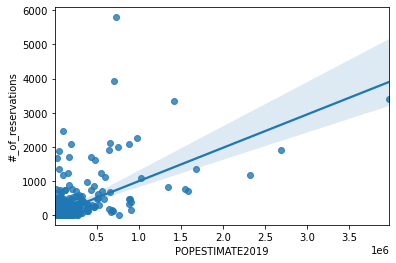

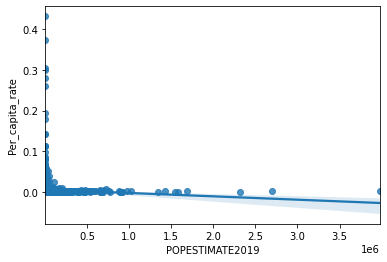

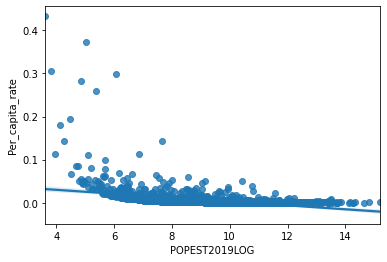

In [3]:
df, plot1, plot2, plot3 = Merge_pop_reserv_data('US_city_pop_clean.csv','Reservation_by_city_all_more_5_2020.csv', 'Merged_pop_reserv_all_more_5.csv')

In [4]:
df.loc[(df["POPESTLOG"] > 8) & (df["#_of_reservations"] > 1000)]

KeyError: 'POPESTLOG'

In [5]:
POPEST_2019 = df.loc[(df["POPESTIMATE2019"] < 500000)]


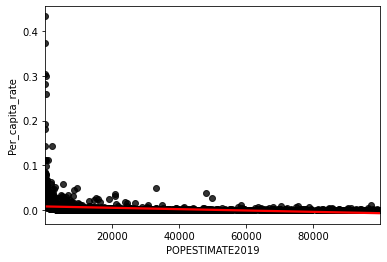

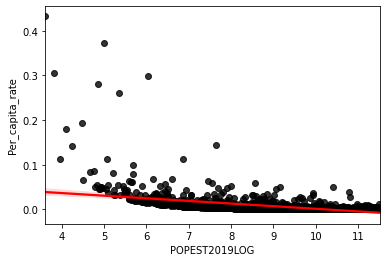

In [19]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import pyplot

Pop_df = pd.read_csv('US_city_pop_clean.csv',index_col=[0])
Reserv_df = pd.read_csv('Reservation_by_city_all_more_5_2020.csv',index_col=[0])
merge_df = pd.merge(Pop_df,Reserv_df,how='right',left_on=['STNAME','Name'], right_on=['state','city'])
merge_df = merge_df[['city','STNAME', 'POPESTIMATE2019','#_of_reservations']]
merge_df = merge_df.dropna()

POPEST_2019 = df.loc[(df["POPESTIMATE2019"] < 100000)]
    
plot1 = sns.regplot(data=POPEST_2019, x='POPESTIMATE2019', y='Per_capita_rate', scatter_kws={"color": "black"}, line_kws={"color": "red"})
plt.show(plot1)

plot1 = sns.regplot(data=POPEST_2019, x='POPEST2019LOG', y='Per_capita_rate',scatter_kws={"color": "black"}, line_kws={"color": "red"})
plt.show(plot1)

Per_capita_rate_log= np.log(POPEST_2019['Per_capita_rate'])



In [15]:
Pop_df


NameError: name 'fit_exp_nonlinear' is not defined

In [42]:
POPEST_2019.dtypes

city                  object
STNAME                object
POPESTIMATE2019      float64
#_of_reservations      int64
Per_capita_rate      float64
POPEST2019LOG        float64
dtype: object

Text(0.5, 1.0, 'Original Data')

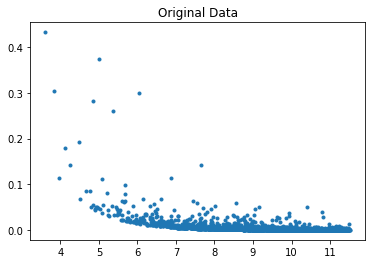

In [56]:
import numpy as np
import scipy.optimize
import matplotlib.pyplot as plt

xs = POPEST_2019['POPEST2019LOG']
ys = POPEST_2019['Per_capita_rate']
plt.plot(xs, ys, '.')
plt.title("Original Data")

R² = 0.51410389452949
Y = 0.3164067707492258 * e^(-0.007893253116827021 * x) + 0.0035900827613971477
Tau = 6334.52383446425 µs


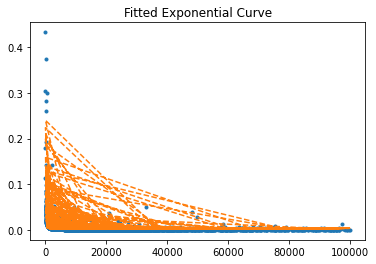

[-1.50382245e-07  8.62887040e-03]


TypeError: unsupported operand type(s) for ^: 'float' and 'float'